In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)


In [2]:
df = pd.read_csv(r"D:\tasks\cars_data (1).csv")
df.head()


,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [3]:
print('Dataset shape:', df.shape)
df.info()


Dataset shape: (1000, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            1000 non-null   str    
 1   Year             1000 non-null   int64  
 2   Mileage          1000 non-null   int64  
 3   Engine_Size      980 non-null    float64
 4   Fuel_Type        1000 non-null   str    
 5   Transmission     1000 non-null   str    
 6   Previous_Owners  1000 non-null   int64  
 7   Price            1000 non-null   int64  
dtypes: float64(1), int64(4), str(3)
memory usage: 62.6 KB


In [4]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Brand,1000,8,Mercedes,146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,1000.0,NaN,NaN,NaN,2016.3,4.056162,2010.0,2013.0,2016.0,2020.0,2023.0
Mileage,1000.0,NaN,NaN,NaN,104551.675,56197.795061,5207.0,54239.25,105298.0,155468.25,199812.0
Engine_Size,980.0,NaN,NaN,NaN,2.494592,0.86523,1.0,1.8,2.5,3.225,4.0
Fuel_Type,1000,4,Petrol,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,1000,2,Automatic,510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Previous_Owners,1000.0,NaN,NaN,NaN,3.062,1.404325,1.0,2.0,3.0,4.0,5.0
Price,1000.0,NaN,NaN,NaN,8473.646,6292.910864,3000.0,4069.5,6439.0,10905.5,43994.0


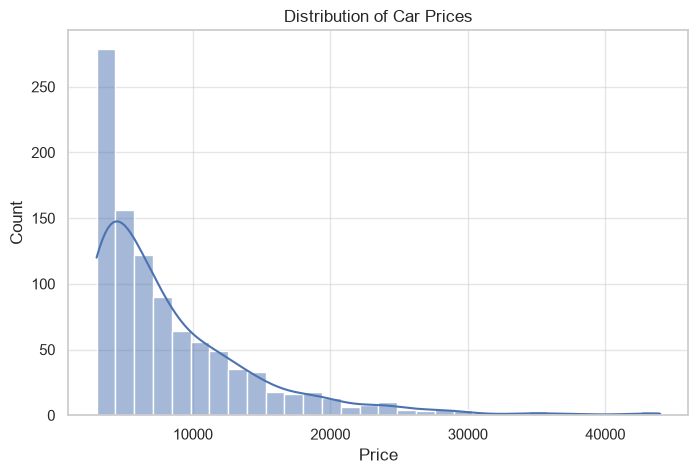

In [5]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True)
plt.title('Distribution of Car Prices')
plt.show()


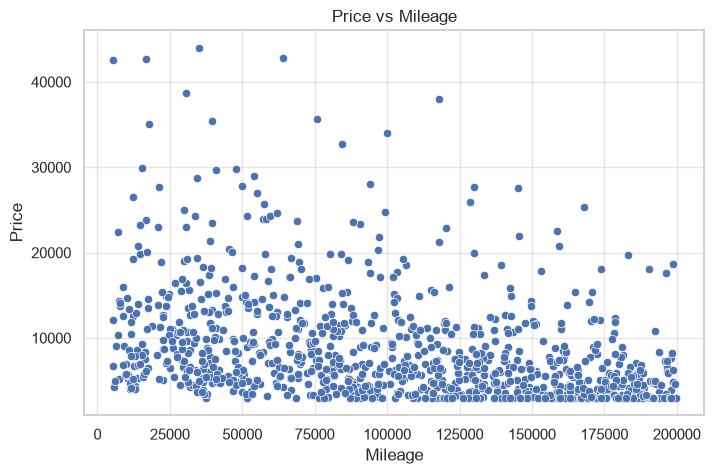

In [6]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Mileage', y='Price')
plt.title('Price vs Mileage')
plt.show()


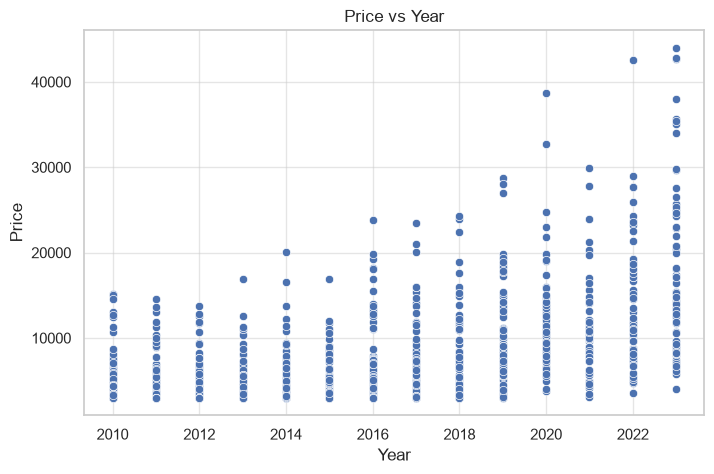

In [7]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Year', y='Price')
plt.title('Price vs Year')
plt.show()


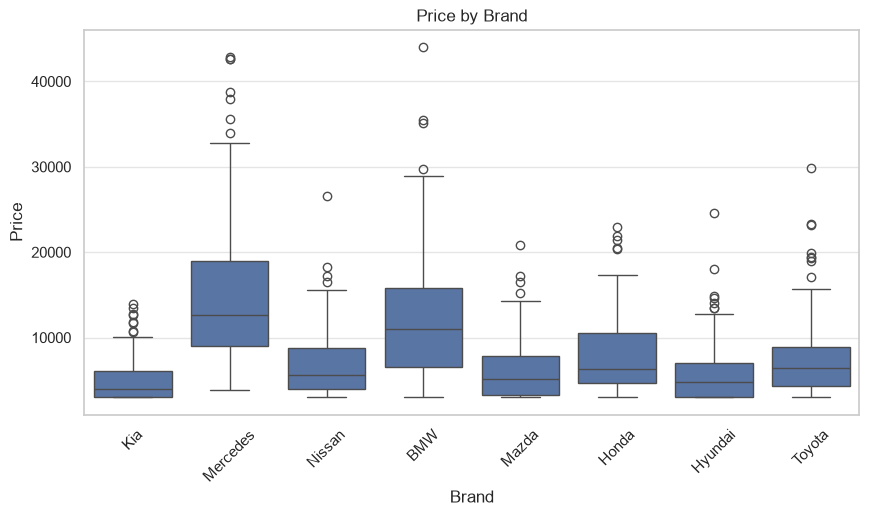

In [8]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='Brand', y='Price')
plt.xticks(rotation=45)
plt.title('Price by Brand')
plt.show()


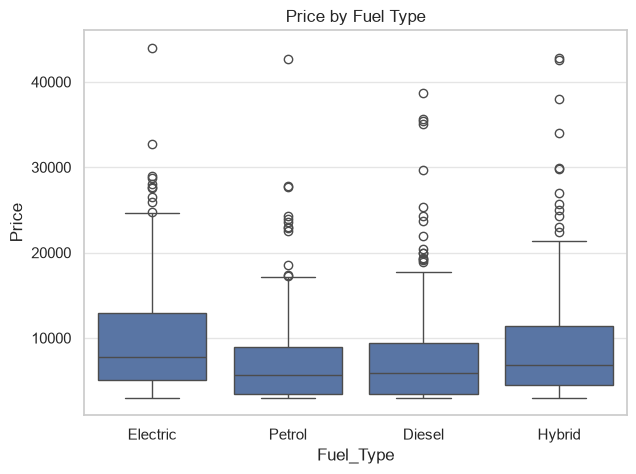

In [9]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Fuel_Type', y='Price')
plt.title('Price by Fuel Type')
plt.show()


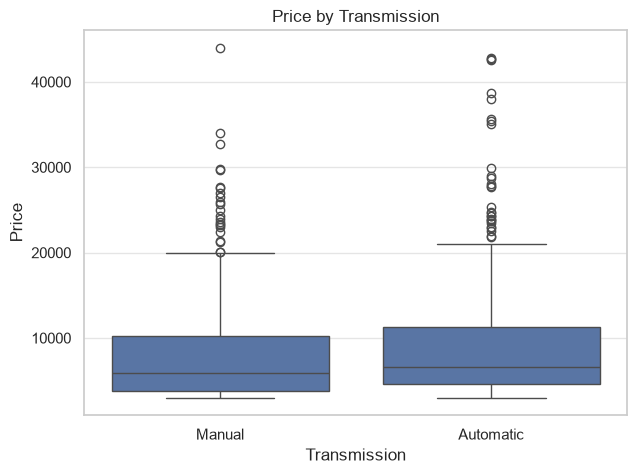

In [10]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Transmission', y='Price')
plt.title('Price by Transmission')
plt.show()


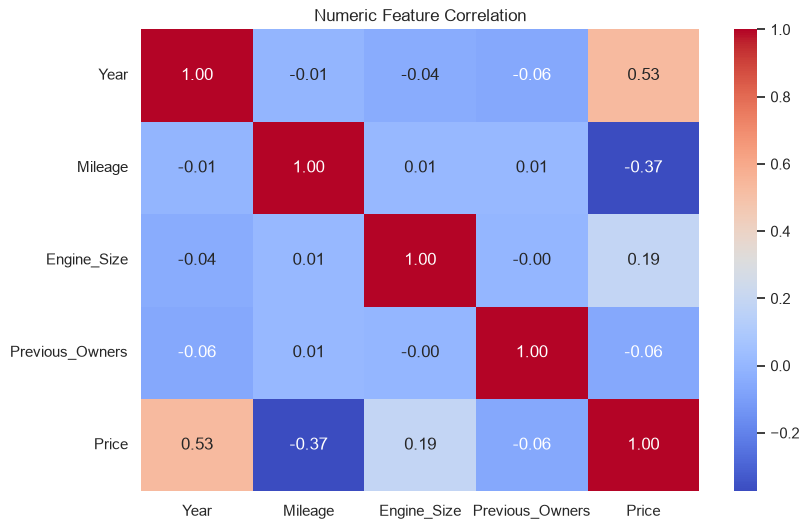

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(9,6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Numeric Feature Correlation')
plt.show()


In [12]:
df.isnull().sum()


Brand               0
Year                0
Mileage             0
Engine_Size        20
Fuel_Type           0
Transmission        0
Previous_Owners     0
Price               0
dtype: int64

In [13]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().copy()
print('Shape after removing duplicates:', df.shape)


Duplicate rows: 0
Shape after removing duplicates: (1000, 8)


In [14]:
target = 'Price'
X = df.drop(columns=[target])
y = df[target]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)


Numeric features: ['Year', 'Mileage', 'Engine_Size', 'Previous_Owners']
Categorical features: ['Brand', 'Fuel_Type', 'Transmission']


In [15]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Training set:', X_train.shape)
print('Test set:', X_test.shape)


Training set: (800, 7)
Test set: (200, 7)


In [17]:
models = {
    'Dummy': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

cv_results = []
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
    cv_results.append({'Model': name, 'CV MAE': -scores.mean(), 'CV MAE Std': scores.std()})

cv_results_df = pd.DataFrame(cv_results).sort_values('CV MAE')
cv_results_df


,Model,CV MAE,CV MAE Std
7,Gradient Boosting,1340.833283,113.364646
6,Extra Trees,1370.138619,112.109175
5,Random Forest,1561.779031,169.884563
2,Ridge,2143.990462,176.217039
3,Lasso,2146.541218,178.298161
1,Linear Regression,2146.918540,178.677143
4,Decision Tree,2381.975000,124.087066
0,Dummy,4547.971758,129.238306


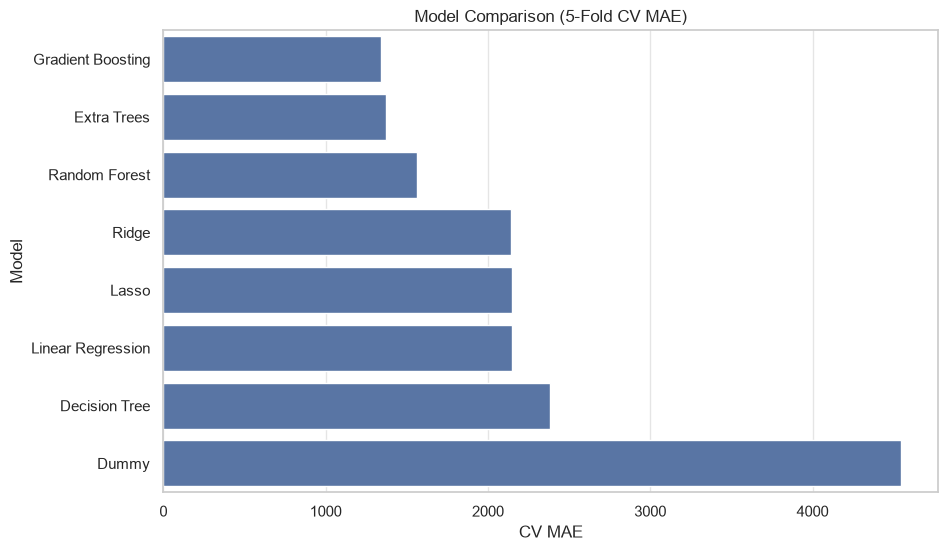

In [18]:
plt.figure(figsize=(10,6))
sns.barplot(data=cv_results_df, x='CV MAE', y='Model')
plt.title('Model Comparison (5-Fold CV MAE)')
plt.show()


In [19]:
best_model_name = cv_results_df.iloc[0]['Model']
best_estimator = models[best_model_name]
best_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', best_estimator)])
best_pipeline.fit(X_train, y_train)

print('Best model:', best_model_name)


Best model: Gradient Boosting


In [20]:
predictions = best_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

metrics_df = pd.DataFrame({'Metric':['MAE','RMSE','R2'], 'Value':[mae,rmse,r2]})
metrics_df


,Metric,Value
0,MAE,1360.187615
1,RMSE,2238.336266
2,R2,0.878658


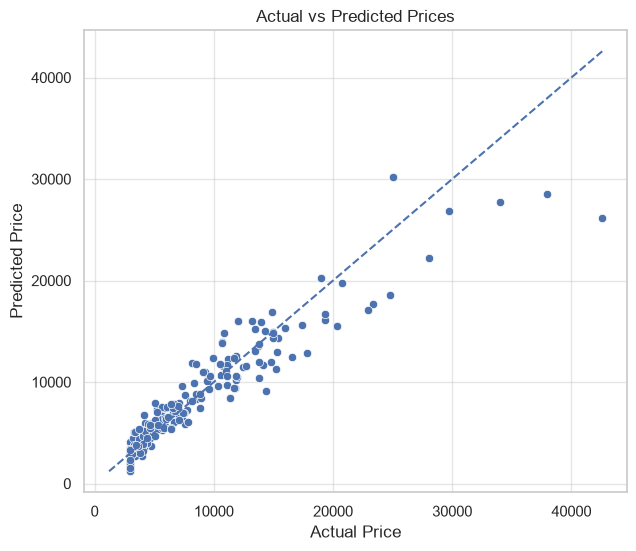

In [21]:
plt.figure(figsize=(7,6))
sns.scatterplot(x=y_test, y=predictions)
lims = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
plt.plot(lims, lims, '--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Prices')
plt.show()


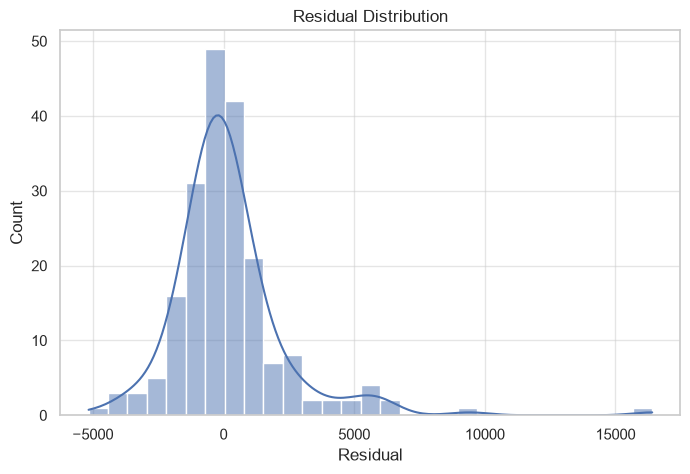

In [22]:
residuals = y_test - predictions
plt.figure(figsize=(8,5))
sns.histplot(residuals, kde=True)
plt.title('Residual Distribution')
plt.xlabel('Residual')
plt.show()


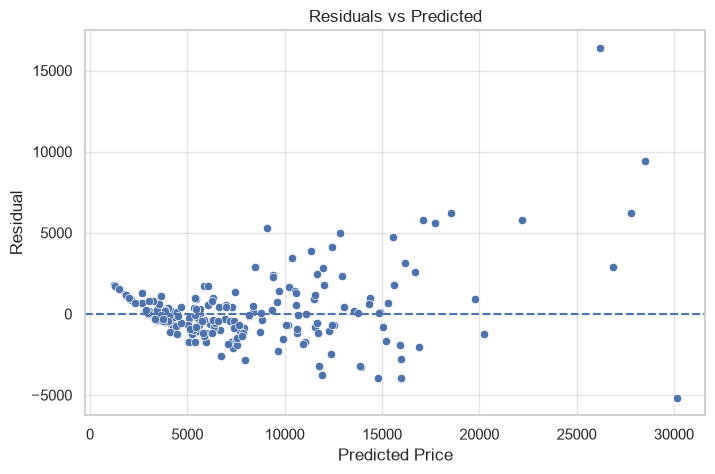

In [23]:
plt.figure(figsize=(8,5))
sns.scatterplot(x=predictions, y=residuals)
plt.axhline(0, linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted')
plt.show()


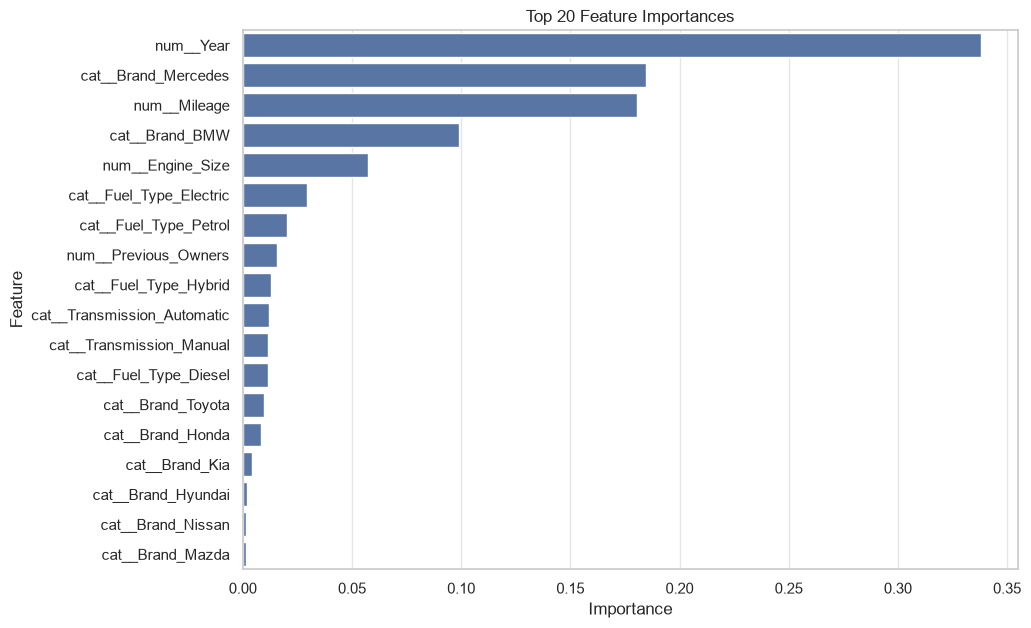

In [24]:
importance_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', ExtraTreesRegressor(n_estimators=200, random_state=42))
])
importance_pipe.fit(X_train, y_train)

feature_names = importance_pipe.named_steps['preprocessor'].get_feature_names_out()
importances = importance_pipe.named_steps['model'].feature_importances_
importance_df = pd.DataFrame({'Feature':feature_names, 'Importance':importances}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10,7))
sns.barplot(data=importance_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances')
plt.show()


In [25]:
print(f'Chosen model: {best_model_name}')
print(f'Test MAE: {mae:.2f}')
print(f'Test RMSE: {rmse:.2f}')
print(f'Test R2: {r2:.3f}')


Chosen model: Gradient Boosting
Test MAE: 1360.19
Test RMSE: 2238.34
Test R2: 0.879
